In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [14]:
df=pd.read_csv('diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [16]:
df.describe()   

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [17]:
(df[cols]==0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [18]:
data=df.copy()

In [19]:
cols=['Glucose','BloodPressure','SkinThickness','Insulin','BMI']

In [20]:
data[cols]=data[cols].replace(0,np.nan)

In [21]:
for col in cols:
    q1=np.nanpercentile(data[col],25)
    q3=np.nanpercentile(data[col],75)   
    iqr=q3-q1
    lower_bound=q1-1.5*iqr  
    upper_bound=q3+1.5*iqr
    outliers=data[(data[col]<lower_bound) | (data[col]>upper_bound)]
    print(f"{col}: Lower Bound={lower_bound}, Upper Bound={upper_bound}")
    print(f"iqr {col}={iqr}")
    print(f"Number of outliers in {col}: {len(outliers)}")

Glucose: Lower Bound=36.0, Upper Bound=204.0
iqr Glucose=42.0
Number of outliers in Glucose: 0
BloodPressure: Lower Bound=40.0, Upper Bound=104.0
iqr BloodPressure=16.0
Number of outliers in BloodPressure: 14
SkinThickness: Lower Bound=1.0, Upper Bound=57.0
iqr SkinThickness=14.0
Number of outliers in SkinThickness: 3
Insulin: Lower Bound=-94.375, Upper Bound=360.625
iqr Insulin=113.75
Number of outliers in Insulin: 24
BMI: Lower Bound=13.849999999999998, Upper Bound=50.25
iqr BMI=9.100000000000001
Number of outliers in BMI: 8


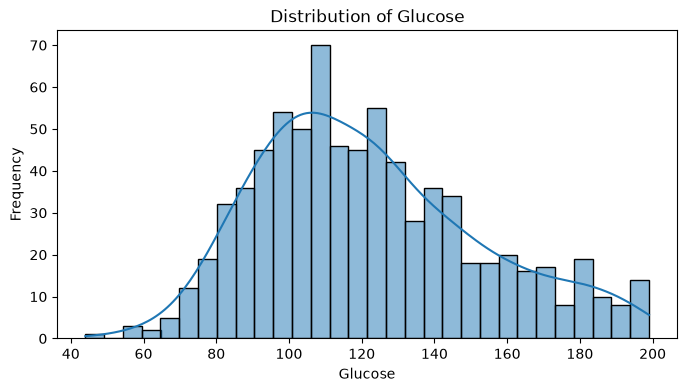

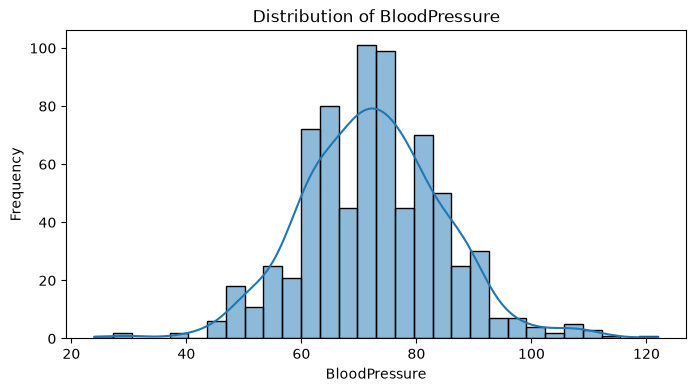

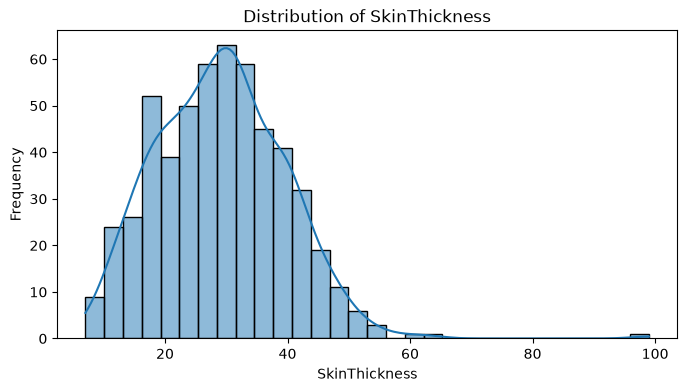

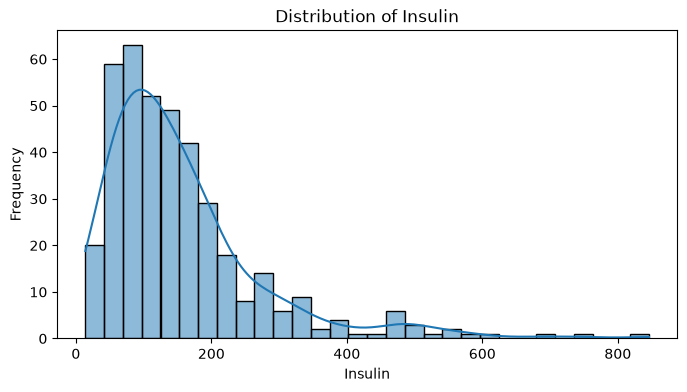

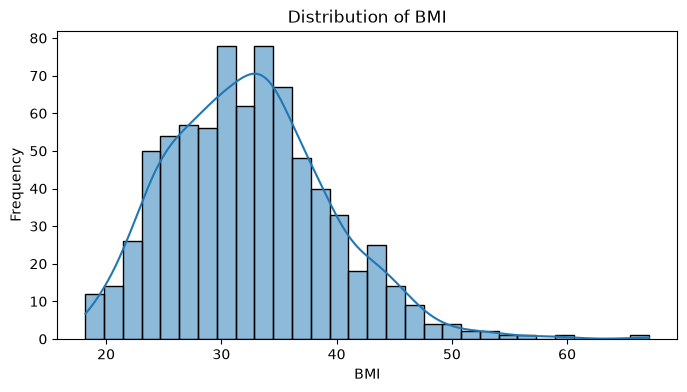

In [22]:
for col in cols:
    plt.figure(figsize=(8,4))
    sns.histplot(data[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

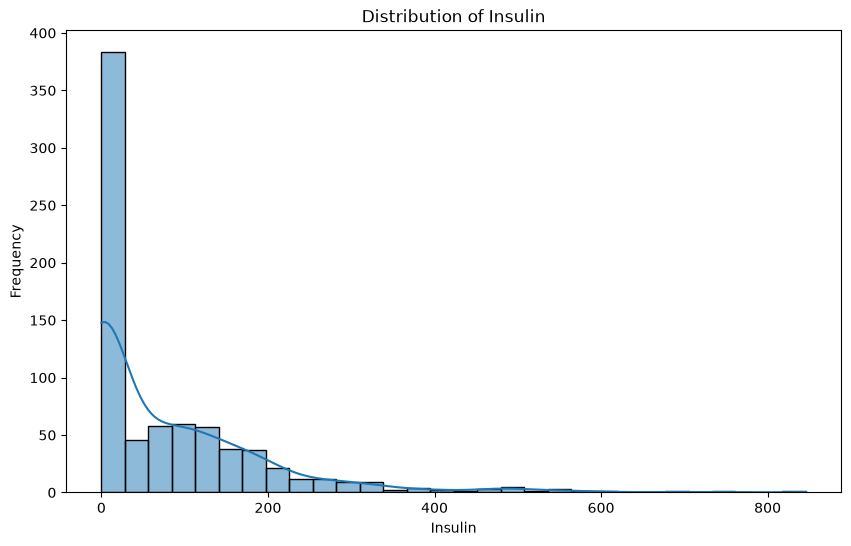

In [23]:
plt.figure(figsize=(10,6))
sns.histplot(df['Insulin'], kde=True, bins=30)
plt.title('Distribution of Insulin')
plt.xlabel('Insulin')
plt.ylabel('Frequency')
plt.show()

In [24]:
for col in cols:
    q1=np.nanpercentile(data[col],25)
    q3=np.nanpercentile(data[col],75)   
    iqr=q3-q1
    lower_bound=q1-1.5*iqr  
    upper_bound=q3+1.5*iqr
    outliers=data[(data[col]<lower_bound) | (data[col]>upper_bound)]
    print(f"{col}: Lower Bound={lower_bound}, Upper Bound={upper_bound}")
    print(f"iqr {col}={iqr}")
    print(f"Number of outliers in {col}: {len(outliers)}")

Glucose: Lower Bound=36.0, Upper Bound=204.0
iqr Glucose=42.0
Number of outliers in Glucose: 0
BloodPressure: Lower Bound=40.0, Upper Bound=104.0
iqr BloodPressure=16.0
Number of outliers in BloodPressure: 14
SkinThickness: Lower Bound=1.0, Upper Bound=57.0
iqr SkinThickness=14.0
Number of outliers in SkinThickness: 3
Insulin: Lower Bound=-94.375, Upper Bound=360.625
iqr Insulin=113.75
Number of outliers in Insulin: 24
BMI: Lower Bound=13.849999999999998, Upper Bound=50.25
iqr BMI=9.100000000000001
Number of outliers in BMI: 8


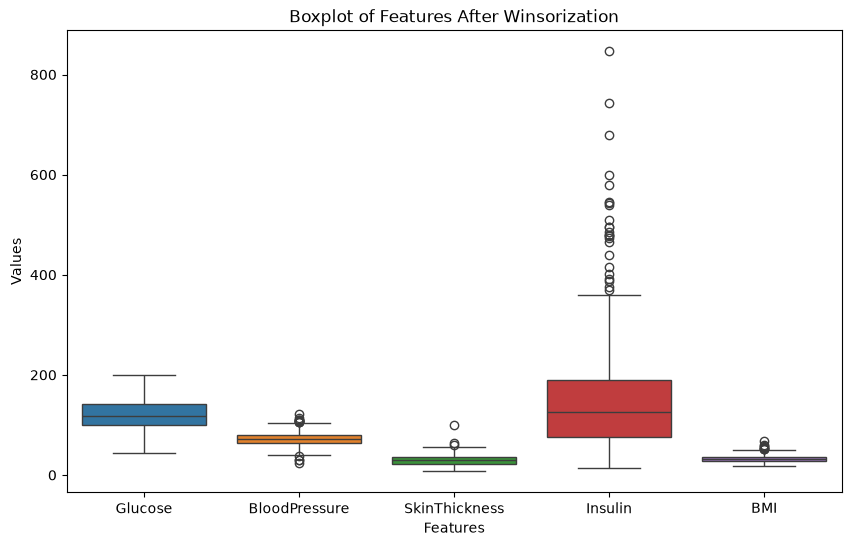

In [25]:
plt.figure(figsize=(10,6))
sns.boxplot(data=data[cols])
plt.title('Boxplot of Features After Winsorization')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()

In [26]:
df_winsor = data.copy()

In [27]:
for col in cols:

    q1 = df_winsor[col].quantile(0.25)
    q3 = df_winsor[col].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    df_winsor[col] = df_winsor[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

In [28]:
df_winsor.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [29]:
for col in cols:

    print(f"\n{col}")

    print("Before Winsorization:")
    print(data[col].describe())

    print("After Winsorization:")
    print(df_winsor[col].describe())


Glucose
Before Winsorization:
count    763.000000
mean     121.686763
std       30.535641
min       44.000000
25%       99.000000
50%      117.000000
75%      141.000000
max      199.000000
Name: Glucose, dtype: float64
After Winsorization:
count    763.000000
mean     121.686763
std       30.535641
min       44.000000
25%       99.000000
50%      117.000000
75%      141.000000
max      199.000000
Name: Glucose, dtype: float64

BloodPressure
Before Winsorization:
count    733.000000
mean      72.405184
std       12.382158
min       24.000000
25%       64.000000
50%       72.000000
75%       80.000000
max      122.000000
Name: BloodPressure, dtype: float64
After Winsorization:
count    733.000000
mean      72.375171
std       11.973207
min       40.000000
25%       64.000000
50%       72.000000
75%       80.000000
max      104.000000
Name: BloodPressure, dtype: float64

SkinThickness
Before Winsorization:
count    541.000000
mean      29.153420
std       10.476982
min        7.000000
2

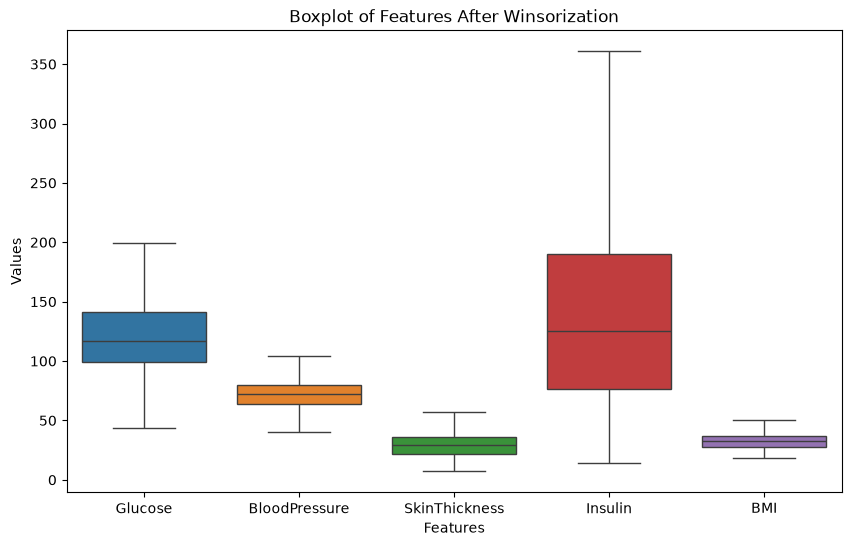

In [30]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_winsor[cols])
plt.title('Boxplot of Features After Winsorization')
plt.xlabel('Features')
plt.ylabel('Values')
plt.show()

In [31]:
df_winsor.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [32]:
df_winsor.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [33]:
X = df_winsor.drop(columns=['Outcome'])
y = df_winsor['Outcome']

In [34]:
X.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


In [35]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [36]:
knn = KNNImputer(
    n_neighbors=5,
    weights='distance'
)
X_imputed = knn.fit_transform(X_scaled)

In [37]:
X_imputed = scaler.inverse_transform(X_imputed)

X_imputed = pd.DataFrame(
    X_imputed,
    columns=X.columns,
    index=X.index
)

In [38]:
X_imputed.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

In [39]:
X_imputed.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.000000,228.392690,33.6,0.627,50.0
1,1.0,85.0,66.0,29.000000,63.650729,26.6,0.351,31.0
2,8.0,183.0,64.0,31.104444,200.797093,23.3,0.672,32.0
3,1.0,89.0,66.0,23.000000,94.000000,28.1,0.167,21.0
4,0.0,137.0,40.0,35.000000,168.000000,43.1,2.288,33.0


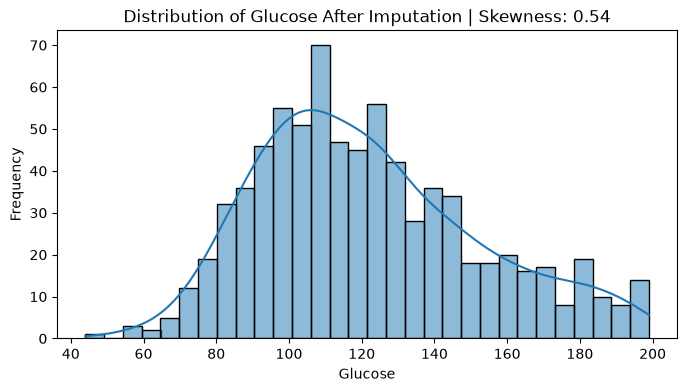

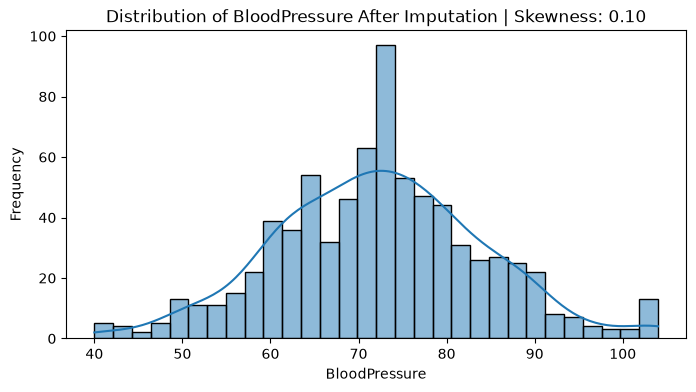

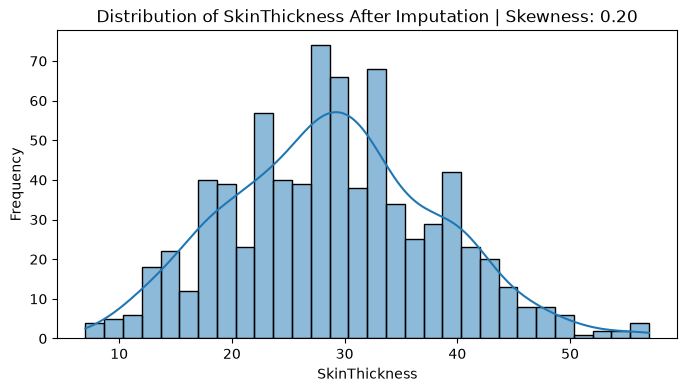

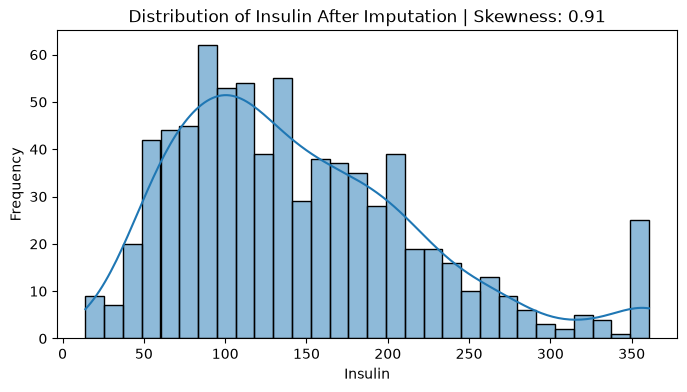

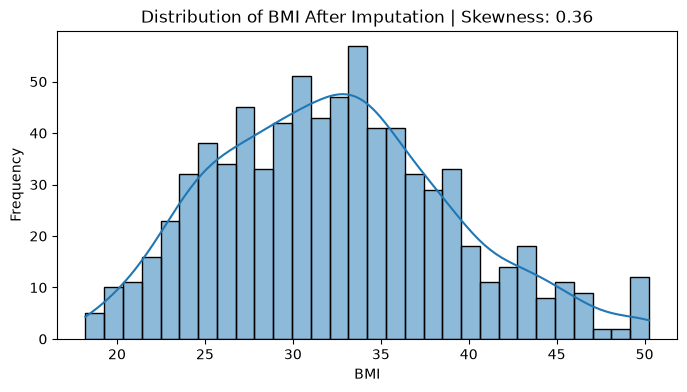

In [40]:
for col in cols:
    plt.figure(figsize=(8,4))
    sns.histplot(X_imputed[col], kde=True, bins=30)
    plt.title(f'Distribution of {col} After Imputation | Skewness: {X_imputed[col].skew():.2f}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()


In [41]:
print("skewness before winsorization and knn-imputing of each column.")
for col in cols:
    print(f" Skewness of {col} :{data[col].skew()}")

skewness before winsorization and knn-imputing of each column.
 Skewness of Glucose :0.5309885349396287
 Skewness of BloodPressure :0.1341527317195934
 Skewness of SkinThickness :0.690619013984192
 Skewness of Insulin :2.166463843812443
 Skewness of BMI :0.5939697505712659


In [42]:
print("skewness after winsorization and knn-imputing of each column.")
for col in cols:
    print(f" Skewness of {col} :{X_imputed[col].skew()}")

skewness after winsorization and knn-imputing of each column.
 Skewness of Glucose :0.5384591275926149
 Skewness of BloodPressure :0.10038231506520943
 Skewness of SkinThickness :0.19779459719778406
 Skewness of Insulin :0.9105738594609513
 Skewness of BMI :0.3565699784413907


In [43]:
df_cleaned=X_imputed.copy()

In [44]:
df_cleaned.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,35.000000,228.392690,33.6,0.627,50.0
1,1.0,85.0,66.0,29.000000,63.650729,26.6,0.351,31.0
2,8.0,183.0,64.0,31.104444,200.797093,23.3,0.672,32.0
3,1.0,89.0,66.0,23.000000,94.000000,28.1,0.167,21.0
4,0.0,137.0,40.0,35.000000,168.000000,43.1,2.288,33.0


In [45]:
df_cleaned['Outcome']=y

In [46]:
df_cleaned.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

In [47]:
df_cleaned.shape

(768, 9)

In [48]:
df_cleaned.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.000000,35.000000,228.392690,33.600000,0.627,50.0,1
1,1.0,85.0,66.000000,29.000000,63.650729,26.600000,0.351,31.0,0
2,8.0,183.0,64.000000,31.104444,200.797093,23.300000,0.672,32.0,1
3,1.0,89.0,66.000000,23.000000,94.000000,28.100000,0.167,21.0,0
4,0.0,137.0,40.000000,35.000000,168.000000,43.100000,2.288,33.0,1
5,5.0,116.0,74.000000,22.905522,118.200265,25.600000,0.201,30.0,0
6,3.0,78.0,50.000000,32.000000,88.000000,31.000000,0.248,26.0,1
7,10.0,115.0,75.722414,31.173371,192.371105,35.300000,0.134,29.0,0
8,2.0,197.0,70.000000,45.000000,360.625000,30.500000,0.158,53.0,1
9,8.0,125.0,96.000000,29.489472,200.438418,34.023066,0.232,54.0,1


In [49]:
df_cleaned.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [50]:
df_cleaned.to_csv("diabetes_dataset_postcleaning.csv", index=False)